# Auditoría conformal bajo cambio de covariables

## Resumen
Con n=80, el método ponderado correcto alcanza 94,717% de cobertura marginal frente a 51,616% sin ponderar. Pero 26,3255% de intervalos son infinitos: cobertura no equivale a utilidad. Con cambio condicional la cobertura cae a 79,619%. Simulación sintética; no evidencia operacional.

## Contexto y métodos

### Supuestos clave
Predictor $\hat\mu(x)=0$ fijado antes de calibración. $X\sim Bernoulli(0.1)$ en calibración y $Bernoulli(0.8)$ en destino. $Y|X\sim N(0,\sigma_X^2)$, $\sigma_0=1$, $\sigma_1=4$. Pesos $w(x)=q(x)/p(x)$ conocidos. Score $s_i=|y_i|$.

Umbral correcto:
$$q(x)=Q_{1-\alpha}\left(\sum_i \frac{w_i}{\sum_jw_j+w(x)}\delta_{s_i}+\frac{w(x)}{\sum_jw_j+w(x)}\delta_{+\infty}\right).$$
El baseline ingenuo omite la masa test; el baseline sin ponderar usa pesos uno y corrección finita. La garantía es marginal, no por grupo. El aporte es auditoría reproducible, no un algoritmo nuevo. Fuentes en `referencias.bib`, especialmente Tibshirani et al. (2019).

## Datos y configuración
Datos sintéticos independientes; 100 calibraciones por escenario, 2.000 puntos de prueba por calibración. Métodos pareados. Semilla fija; error Monte Carlo se calcula entre calibraciones, no tratando 200.000 puntos como independientes.

In [1]:
import json
from pathlib import Path
from IPython.display import display, Image
r = json.loads(Path("results/summary.json").read_text())
r["config"]

Out[0]: 
{'seed': 20261023,
 'alpha': 0.1,
 'source_high': 0.1,
 'target_high': 0.8,
 'calibration_sizes': [40, 80, 320],
 'test_size': 2000,
 'repeats': 100,
 'predictor': 'fixed oracle conditional mean zero',
 'dataset': 'synthetic Bernoulli covariate, heteroskedastic Gaussian residual; no private data',
 'hypothesis': 'correct_weighted coverage >=0.88 and improves >=0.10 over unweighted at n=80 under covariate_shift'}


## Resultados
La tabla permite auditar cobertura marginal, cobertura del grupo de ruido alto, proporción finita y ancho entre intervalos finitos. Si existe cualquier intervalo infinito, el ancho medio incondicional es infinito: no se debe interpretar el ancho finito como coste total.

In [2]:
for row in r["summary"]:
    if row["n"] == 80:
        print(row["scenario"], row["method"], "coverage=", round(row["coverage"], 5), "finite_rate=", round(row["finite_rate"], 5), "finite_width=", round(row["finite_mean_width"], 3))

no_shift unweighted coverage= 0.8999 finite_rate= 1.0 finite_width= 4.292
no_shift naive_weighted coverage= 0.88627 finite_rate= 1.0 finite_width= 3.995
no_shift correct_weighted coverage= 0.8999 finite_rate= 1.0 finite_width= 4.292
covariate_shift unweighted coverage= 0.51616 finite_rate= 1.0 finite_width= 4.292
covariate_shift naive_weighted coverage= 0.86267 finite_rate= 1.0 finite_width= 12.031
covariate_shift correct_weighted coverage= 0.94717 finite_rate= 0.73674 finite_width= 13.808
conditional_shift unweighted coverage= 0.31094 finite_rate= 1.0 finite_width= 4.292
conditional_shift naive_weighted coverage= 0.62312 finite_rate= 1.0 finite_width= 12.031
conditional_shift correct_weighted coverage= 0.79619 finite_rate= 0.73674 finite_width= 13.808


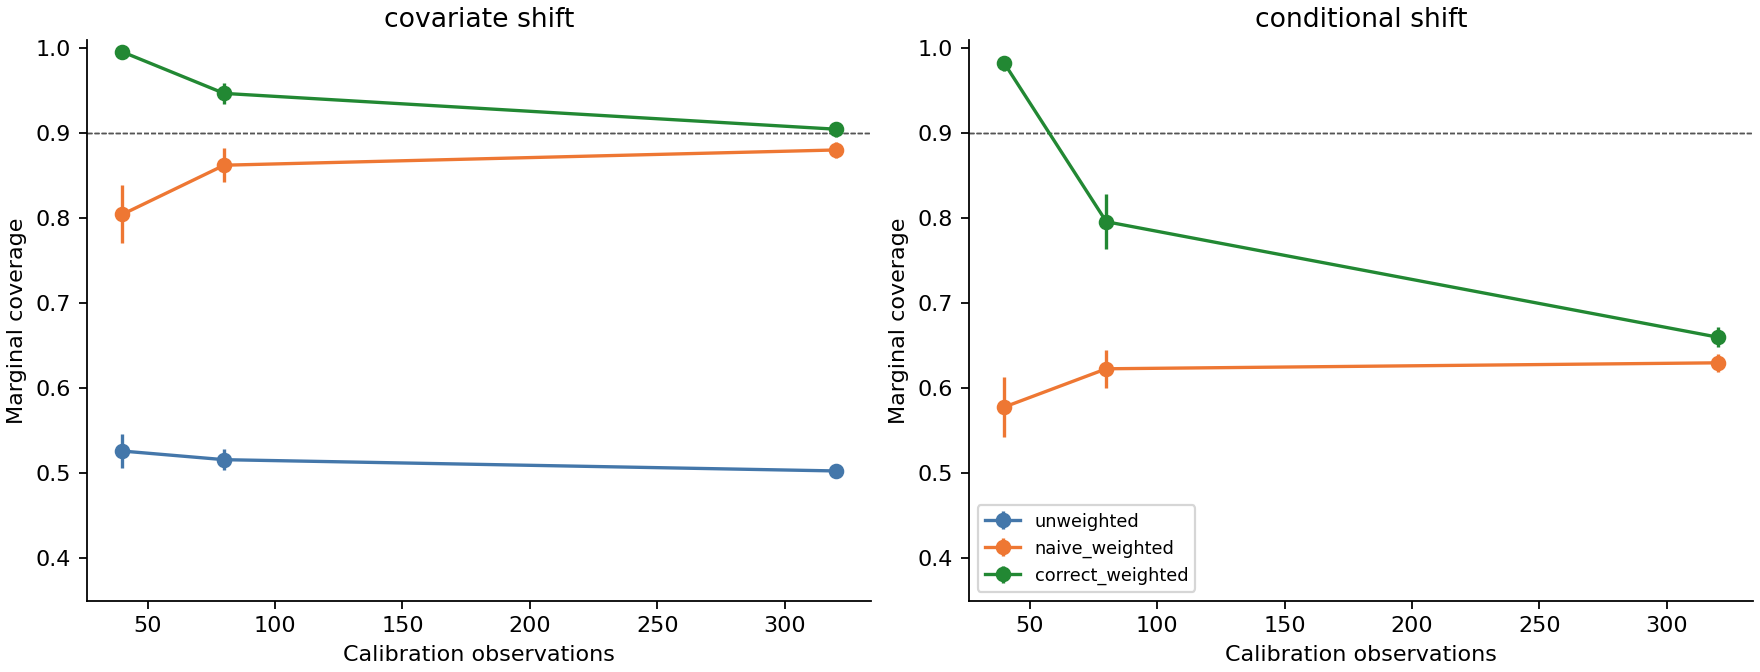

In [3]:
display(Image(filename="results/coverage.png"))

### Lectura de la figura
Las barras son ±1,96 errores estándar Monte Carlo entre 100 réplicas; no son garantía matemática ni intervalos simultáneos. El método correcto resulta conservador con n=40 porque devuelve muchos intervalos infinitos. Al aumentar n, mejora la utilidad pero se revela el fallo ante cambio condicional.

In [4]:
rows = r["summary"]
def row(scenario, method, n=80):
    return next(x for x in rows if x["scenario"] == scenario and x["method"] == method and x["n"] == n)
correct = row("covariate_shift", "correct_weighted")
baseline = row("covariate_shift", "unweighted")
assert correct["coverage"] >= .88
assert correct["coverage"] - baseline["coverage"] >= .10
assert row("conditional_shift", "correct_weighted")["coverage"] < .88
assert correct["finite_rate"] < 1
print("Hipótesis sintética confirmada; falsificación condicional e inutilidad parcial detectadas.")
r["execution"]

Hipótesis sintética confirmada; falsificación condicional e inutilidad parcial detectadas.
Out[0]: 
{'seconds': 1.0765255250000791,
 'python_peak_bytes': 1989503,
 'process_maxrss_kib': 56660,
 'python': '3.12.14',
 'numpy': '2.3.5',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39',
 'processor': 'x86_64',
 'cpu_count': 9,
 'notes': 'tracemalloc tracks Python allocations; RSS is whole-process peak, not method-specific'}


## Conclusiones y límites
La masa test evita presentar cuantiles finitos injustificados cuando el solapamiento es débil. No basta para obtener cobertura por grupo ni robustez a cambios de Y|X. Los pesos son oráculo; no se evaluó estimación de ratios, datos reales ni operación. El siguiente experimento debe incorporar pesos estimados con muestra no etiquetada independiente y una regla explícita de derivación humana cuando el intervalo sea infinito.